# Validation-only water threshold experiment

The U-Net produces a water score for every pixel. A threshold converts that score into a binary water mask. Lowering the threshold accepts more pixels as water; raising it requires stronger evidence. These scores have not been established as calibrated probabilities.

**Predefined protocol:** evaluate thresholds 0.10 through 0.90 in steps of 0.05. Select maximum pooled validation water IoU; ties go to the threshold closest to 0.50, then the smaller threshold. Keep the checkpoint, preprocessing, and label-only mask fixed. Do not inspect held-out scores to choose the threshold or refine the grid after seeing results.

The validation split has already been used for checkpoint selection. Scores after threshold selection describe development results, not independent generalisation. Existing test/Bolivia results refer to threshold 0.50.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
# Set SEN1FLOODS11_ROOT to use a different local dataset location.
root = Path(os.environ.get("SEN1FLOODS11_ROOT", str(Path.home() / ".cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11")))
assert (root / "splits/flood_test_data.csv").is_file(), f"Dataset not found: {root}"
print("Dataset:", root)


Dataset: /Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11


In [2]:
import csv
import hashlib
import json
from importlib.metadata import version
import numpy as np
import torch
import matplotlib.pyplot as plt
from floodrisk.datasets.sen1floods11 import Sen1Floods11
from floodrisk.models.unet import build_unet

# Declared before looking at results: maximise pooled water IoU on this grid.
# Ties: closest to 0.50, then smaller threshold. No fine-grid follow-up.
thresholds = [round(i / 100, 2) for i in range(10, 91, 5)]
selection_rule = "max pooled validation water IoU; ties closest to 0.50, then lower threshold"
out = PROJECT / "reports/m1-s1-kaggle-365653491/threshold_sweep"
out.mkdir(exist_ok=True)
checkpoint = PROJECT / "best.pt"
checkpoint_hash = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
reference = json.loads((out.parent / "validation_audit/summary.json").read_text())
assert checkpoint_hash == reference["checkpoint_sha256"]
torch.set_num_threads(4)
model = build_unet(pretrained=False)
model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True), strict=True)
model.eval()
ds = Sen1Floods11(root, "valid")
counts = {t: dict(tp=0, fp=0, fn=0, tn=0) for t in thresholds}
for i in range(len(ds)):
    x, y = ds[i]
    y = y.numpy()
    valid = y != -1
    truth = y[valid] == 1
    with torch.inference_mode():
        probs = model(x.unsqueeze(0)).sigmoid()[0, 0].numpy()[valid]
    assert np.isfinite(probs).all()
    for t in thresholds:
        pred = probs > t
        c = counts[t]
        c["tp"] += int((pred & truth).sum())
        c["fp"] += int((pred & ~truth).sum())
        c["fn"] += int((~pred & truth).sum())
        c["tn"] += int((~pred & ~truth).sum())
    if (i + 1) % 20 == 0: print(f"Processed {i+1}/{len(ds)} chips")
rows = []
for t, c in counts.items():
    tp, fp, fn, tn = (c[k] for k in ["tp", "fp", "fn", "tn"])
    water = tp / (tp + fp + fn)
    dry = tn / (tn + fp + fn)
    rows.append(dict(threshold=t, **c, iou_water=water, miou=(water+dry)/2,
                     precision=tp/(tp+fp) if tp+fp else None,
                     recall=tp/(tp+fn) if tp+fn else None))
baseline = next(r for r in rows if r["threshold"] == 0.5)
assert abs(baseline["iou_water"] - reference["results"]["unet_label_only"]["iou_water"]) < 1e-6
assert all(rows[i]["recall"] >= rows[i+1]["recall"] for i in range(len(rows)-1))
assert all(rows[i]["tp"]+rows[i]["fp"] >= rows[i+1]["tp"]+rows[i+1]["fp"] for i in range(len(rows)-1))
assert len({sum(r[k] for k in ["tp","fp","fn","tn"]) for r in rows}) == 1
selected = min(rows, key=lambda r: (-r["iou_water"], abs(r["threshold"]-0.5), r["threshold"]))
with (out / "validation_thresholds.csv").open("w") as f:
    w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
config = dict(checkpoint_sha256=checkpoint_hash, architecture="unet_resnet34", in_channels=2,
              threshold=selected["threshold"], comparison="probability > threshold",
              selection_split="valid", selection_rule=selection_rule, grid=thresholds,
              label_mask="label != -1", split_chips=len(ds),
              split_csv_sha256=hashlib.sha256((root / "splits/flood_valid_data.csv").read_bytes()).hexdigest(),
              environment={m: version(m) for m in ["torch", "numpy", "rasterio", "segmentation-models-pytorch"]},
              validation_selected=selected, validation_baseline=baseline,
              preprocessing=dict(vv_clip=[-30,5],vh_clip=[-42,-5],mean=[-10.394,-17.232],std=[4.020,4.691],nan_fill_normalized=0),
              held_out_status="Not evaluated for this selected threshold")
(out / "selected_config.json").write_text(json.dumps(config,indent=2)+"\n")
print("Baseline:",baseline)
print("Selected:",selected)
print("Validation water IoU change, percentage points:",100*(selected["iou_water"]-baseline["iou_water"]))


/Users/mac/Documents/Ml PROJECTS/Flood-Risk-Mapper/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Processed 20/89 chips


Processed 40/89 chips


Processed 60/89 chips


Processed 80/89 chips


Baseline: {'threshold': 0.5, 'tp': 1807775, 'fp': 384470, 'fn': 429830, 'tn': 17672650, 'iou_water': 0.6894444285537218, 'miou': 0.8226985705714362, 'precision': 0.8246227041229425, 'recall': 0.8079062211605712}
Selected: {'threshold': 0.55, 'tp': 1793573, 'fp': 362712, 'fn': 444032, 'tn': 17694408, 'iou_water': 0.6897516725845348, 'miou': 0.8230733020500753, 'precision': 0.8317884695204948, 'recall': 0.8015592564371281}
Validation water IoU change, percentage points: 0.030724403081305862


## Threshold trade-off
The image is saved as a standalone artifact and embedded in the project README. Precision asks how reliable water predictions are; recall asks how much labelled water is recovered.

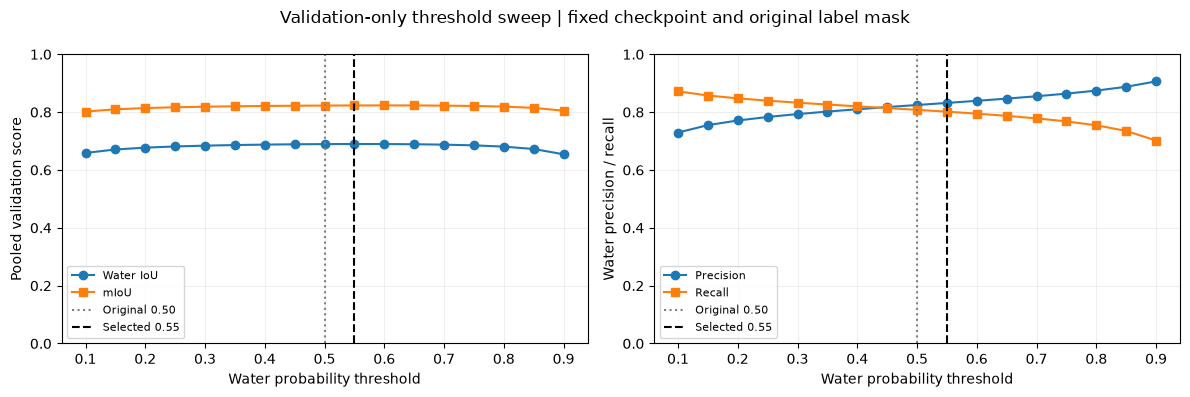

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ts = [r["threshold"] for r in rows]
axes[0].plot(ts, [r["iou_water"] for r in rows], "o-", label="Water IoU")
axes[0].plot(ts, [r["miou"] for r in rows], "s-", label="mIoU")
axes[0].set_ylabel("Pooled validation score")
axes[1].plot(ts, [r["precision"] for r in rows], "o-", label="Precision")
axes[1].plot(ts, [r["recall"] for r in rows], "s-", label="Recall")
axes[1].set_ylabel("Water precision / recall")
for ax in axes:
    ax.axvline(0.5, color="grey", linestyle=":", label="Original 0.50")
    ax.axvline(selected["threshold"], color="black", linestyle="--", label=f"Selected {selected['threshold']:.2f}")
    ax.set_xlabel("Water probability threshold")
    ax.set_ylim(0,1);ax.grid(alpha=0.2);ax.legend(fontsize=8)
fig.suptitle("Validation-only threshold sweep | fixed checkpoint and original label mask")
fig.tight_layout()
fig.savefig(out / "validation_threshold_tradeoff.png",dpi=160,bbox_inches="tight")
plt.show();plt.close(fig)


## What the sweep tells us

The predefined rule selects **0.55**. Validation water IoU increases from **0.689444** to **0.689752**, just **0.0307 percentage points**. Precision increases from **82.46%** to **83.18%**, while recall decreases from **80.79%** to **80.16%**. The broad, nearly flat IoU curve means there is no large threshold-based accuracy gain.

This selection used validation only. `selected_config.json` records the threshold, grid, rule, preprocessing, and checkpoint identity. Held-out evaluation is a separate saved report; do not refine the threshold using its scores. Scores from this development sequence are not evidence from a fresh untouched dataset, because the held-out sets have already been inspected during diagnosis.